# Modelo `reg_bin`: Regresión Logística Binaria
Entrenamiento, optimización (GridSearchCV), evaluación y exportación. Los datos y el split son idénticos a los de `../00_eda_y_comparacion.ipynb`
(80 % entrenamiento / 20 % prueba, estratificado, `random_state=42`).

**Por qué este modelo:** es el *baseline* natural para clasificación binaria. Es rápido, **interpretable** (cada coeficiente indica cuánto empuja la variable hacia "maligno")
y entrega **probabilidades** directamente, útiles para la app. El EDA mostró clases casi separables y fuerte multicolinealidad, por lo que se regulariza (`C`, L1/L2).

In [1]:
# Librerías
import warnings
warnings.filterwarnings("ignore")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Datos y split 80/20

In [2]:
# Carga y limpieza (mismas decisiones que en el EDA): quitar 'id' y la columna vacía 'Unnamed: 32'
df = pd.read_csv("../../../data/data.csv")
df = df.drop(columns=["id"] + [c for c in df.columns if c.startswith("Unnamed")])

# Objetivo: M = 1 (clase positiva, maligno), B = 0
X = df.drop(columns="diagnosis")
y = df["diagnosis"].map({"B": 0, "M": 1})

# Split 80/20 estratificado (conserva la proporción de malignos)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"% maligno -> train: {100*y_train.mean():.1f} | test: {100*y_test.mean():.1f}")

Train: (455, 30) | Test: (114, 30)
% maligno -> train: 37.4 | test: 36.8


## 2. Pipeline y búsqueda de hiperparámetros
Todo el preprocesamiento va **dentro del `Pipeline`**, de modo que en cada fold de la validación cruzada el escalado se ajusta solo con los datos de entrenamiento de ese fold (sin *data leakage*).

Se busca el tipo de regularización (L1 selecciona variables, L2 reduce coeficientes) y su fuerza `C` en una escala logarítmica de 10⁻³ a 10³.

**Métrica de selección:** `F1` de la clase maligna (equilibra precision y recall). También se registra `recall` y `roc_auc`;
la CV es **estratificada de 5 folds**.

In [3]:
pipe = Pipeline([
    ("scaler", StandardScaler()),                      # escalado ajustado solo con train
    ("clf", LogisticRegression(solver="liblinear",     # liblinear admite L1 y L2
                               max_iter=5000, random_state=RANDOM_STATE)),
])

param_grid = {
    "clf__l1_ratio": [0, 1],                           # 0 = penalización L2, 1 = penalización L1
    "clf__C": np.logspace(-3, 3, 13),                  # inversa de la fuerza de regularización
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid = GridSearchCV(
    pipe, param_grid,
    scoring={"f1": "f1", "recall": "recall", "roc_auc": "roc_auc"},
    refit="f1",            # el mejor modelo se elige por F1 y se reentrena con todo train
    cv=cv, n_jobs=-1, return_train_score=False,
)
grid.fit(X_train, y_train)

print("Mejores hiperparámetros:", grid.best_params_)
i = grid.best_index_
print("CV (media ± std) -> F1: %.4f ± %.4f | Recall: %.4f | AUC: %.4f" % (
    grid.cv_results_["mean_test_f1"][i], grid.cv_results_["std_test_f1"][i],
    grid.cv_results_["mean_test_recall"][i], grid.cv_results_["mean_test_roc_auc"][i]))

Mejores hiperparámetros: {'clf__C': np.float64(0.03162277660168379), 'clf__l1_ratio': 0}
CV (media ± std) -> F1: 0.9671 ± 0.0115 | Recall: 0.9529 | AUC: 0.9938


## 3. Evaluación en el conjunto de prueba (20 %)

In [4]:
best_pipe = grid.best_estimator_          # Pipeline completo ya reentrenado con todo el train
y_pred = best_pipe.predict(X_test)
y_prob = best_pipe.predict_proba(X_test)[:, 1]

metricas = {
    "accuracy":  accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred),
    "recall":    recall_score(y_test, y_pred),
    "f1":        f1_score(y_test, y_pred),
    "roc_auc":   roc_auc_score(y_test, y_prob),
}
print(pd.Series(metricas).round(4).to_string())
print()
print(classification_report(y_test, y_pred, target_names=["Benigno", "Maligno"]))

accuracy     0.9825
precision    1.0000
recall       0.9524
f1           0.9756
roc_auc      0.9980

              precision    recall  f1-score   support

     Benigno       0.97      1.00      0.99        72
     Maligno       1.00      0.95      0.98        42

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



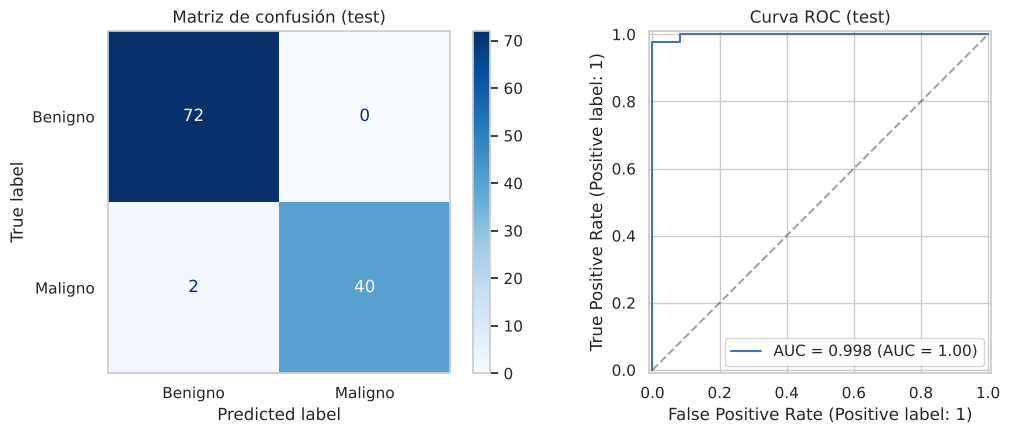

Falsos negativos (malignos no detectados): 2 | Falsos positivos: 0


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Benigno", "Maligno"],
                                        cmap="Blues", ax=axes[0])
axes[0].set_title("Matriz de confusión (test)")
axes[0].grid(False)

RocCurveDisplay.from_predictions(y_test, y_prob, name=f"AUC = {metricas['roc_auc']:.3f}", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[1].set_title("Curva ROC (test)")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"Falsos negativos (malignos no detectados): {fn} | Falsos positivos: {fp}")

## 4. Interpretación del modelo

Coeficientes en cero (L1 los descarta): 0 de 30


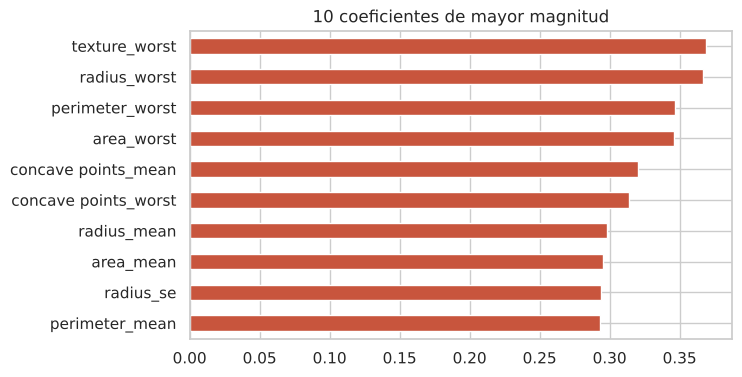

In [6]:
# Coeficientes (variables escaladas): signo + empuja hacia maligno, signo - hacia benigno
coef = pd.Series(best_pipe.named_steps["clf"].coef_[0], index=X.columns)
print("Coeficientes en cero (L1 los descarta):", int((coef == 0).sum()), "de", len(coef))
top = coef.reindex(coef.abs().sort_values(ascending=False).head(10).index)
top.sort_values().plot.barh(color=["#4C9F70" if v < 0 else "#C8553D" for v in top.sort_values()], figsize=(7, 4))
plt.title("10 coeficientes de mayor magnitud"); plt.show()

## 5. Exportación
Se guardan **dos artefactos**, ambos con `joblib`:
- `modelo/modelo.pkl` → solo el **estimador** entrenado (el paso final). Recibe datos **ya preprocesados**.
- `pipeline/pipeline.pkl` → el **Pipeline completo** (preprocesamiento + modelo). **Es el que debe usar la app**: recibe las 30 variables originales sin escalar.

In [7]:
from pathlib import Path
Path("modelo").mkdir(exist_ok=True); Path("pipeline").mkdir(exist_ok=True)

joblib.dump(best_pipe.named_steps["clf"], "modelo/modelo.pkl")
joblib.dump(best_pipe, "pipeline/pipeline.pkl")

# Métricas y configuración, para la comparación final en 00_eda_y_comparacion.ipynb
resumen = {
    "modelo": "reg_bin",
    "mejores_hiperparametros": {k: (v.item() if hasattr(v, "item") else v) for k, v in grid.best_params_.items()},
    "cv_f1": float(grid.cv_results_["mean_test_f1"][grid.best_index_]),
    "cv_recall": float(grid.cv_results_["mean_test_recall"][grid.best_index_]),
    "test": {k: float(v) for k, v in metricas.items()},
    "falsos_negativos": int(fn), "falsos_positivos": int(fp),
    "features": list(X.columns),
}
with open("metricas.json", "w", encoding="utf-8") as f:
    json.dump(resumen, f, indent=2, ensure_ascii=False)
print("Artefactos guardados.")

Artefactos guardados.


### Verificación: recargar los `.pkl` y predecir

In [8]:
# El pipeline recargado debe dar exactamente las mismas predicciones que el original
pipe_cargado = joblib.load("pipeline/pipeline.pkl")
assert np.array_equal(pipe_cargado.predict(X_test), y_pred)
assert np.allclose(pipe_cargado.predict_proba(X_test)[:, 1], y_prob)

# El estimador suelto debe coincidir al alimentarlo con los datos ya transformados
modelo_cargado = joblib.load("modelo/modelo.pkl")
X_test_prep = best_pipe[:-1].transform(X_test)
assert np.array_equal(modelo_cargado.predict(X_test_prep), y_pred)

# Predicción de ejemplo con una fila cruda (como la recibiría la app)
fila = X_test.iloc[[0]]
p = pipe_cargado.predict_proba(fila)[0]
print(f"Real: {'Maligno' if y_test.iloc[0] else 'Benigno'} | "
      f"Predicho: {'Maligno' if p[1] > .5 else 'Benigno'} (P maligno = {p[1]:.3f})")
print("Verificación OK: los .pkl reproducen las predicciones.")

Real: Benigno | Predicho: Benigno (P maligno = 0.025)
Verificación OK: los .pkl reproducen las predicciones.
